# Everything LangChain, LangGraph and LangSmith, end to end

One notebook, seven real-world examples, from a single prompt to multi-agent graphs, with **LangSmith** watching everything.

| # | Example | You will learn | Data used |
|---|---|---|---|
| 1 | Setup and tracing | Keys, `@traceable`, one trace per example | `.env` |
| 2 | Earnings summaries | LCEL: `prompt \| model \| parser`, `.batch()` | `data/earnings_reports.json` |
| 3 | Expense compliance | `create_agent` with **no tools** | `data/expense_policy.md` |
| 4 | Tech-support triage | Tools + **Exa web search** + memory (`InMemorySaver`) | `data/knowledge_base.json` |
| 5 | Long support chat | `SummarizationMiddleware` | `data/long_support_chat.json` |
| 6 | Release-note team | Multi-agent `StateGraph` with a review loop | live web (Exa) |
| 7 | Ticket router | **Subgraphs** (two ways) + `subgraphs=True` streaming | `data/tickets.csv` |
| 8 | Quality check | LangSmith **datasets and evaluation** | `data/earnings_reports.json` |

All company names and data in `data/` are made up for teaching.

## 1. Setup and LangSmith tracing

**Market need:** companies cannot ship an AI feature they cannot see inside. LangSmith records every prompt, model call, tool call and token count, so you can debug in development and monitor in production.

**How tracing works:** with `LANGSMITH_TRACING=true`, every LangChain and LangGraph call is sent to LangSmith automatically. No extra code needed.

**One trace per example:** if you call an agent three times you get three separate traces. To keep a whole flow together, wrap it in a function decorated with `@traceable`. Everything inside that function (agent calls, model calls, tool calls) appears as **children of one trace**. We do this for every example below.

Add these to the `.env` file at the repo root:

```
OPENAI_API_KEY=...
EXA_SEARCH_API_KEY=...
LANGSMITH_TRACING=true
LANGSMITH_API_KEY=...
```

In [1]:
import os
from dotenv import load_dotenv

load_dotenv()  # reads the .env file at the repo root

# Quick check: which keys did we find? (prints True/False, never the key itself)
for key_name in ["OPENAI_API_KEY", "EXA_SEARCH_API_KEY", "LANGSMITH_API_KEY"]:
    print(f"{key_name:20} found: {bool(os.getenv(key_name))}")

print("LangSmith tracing on:", os.getenv("LANGSMITH_TRACING"))

OPENAI_API_KEY       found: True
EXA_SEARCH_API_KEY   found: True
LANGSMITH_API_KEY    found: True
LangSmith tracing on: true


In [2]:
from pathlib import Path
from langsmith import traceable

MODEL_NAME = "openai:gpt-4.1-mini"  # one place to change the model for the whole notebook
DATA_FOLDER = Path("data")

## 2. LangChain LCEL: summarize earnings reports

**Use case:** a financial analyst gets dozens of earnings reports every quarter and wants a 2-bullet summary of each one.

**Market need:** simple, reusable building blocks. LCEL (LangChain Expression Language) joins them with the pipe `|`:

```
prompt  |  model  |  output parser
(fill in)  (think)   (clean text out)
```

Docs: [Models](https://docs.langchain.com/oss/python/langchain/models)

In [3]:
import json

earnings_reports = json.loads((DATA_FOLDER / "earnings_reports.json").read_text())

for report in earnings_reports:
    print(report["company"], "|", report["quarter"], "| revenue", report["revenue"])

Northwind Cloud Systems | Q3 FY2026 | revenue $2.4B
Bluepeak Retail Group | Q3 FY2026 | revenue $5.8B
Helix Biotherapeutics | Q3 FY2026 | revenue $640M
Ironclad Logistics | Q3 FY2026 | revenue $1.1B


In [4]:
from langchain.chat_models import init_chat_model
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser

model = init_chat_model(MODEL_NAME, temperature=0)

summary_prompt = ChatPromptTemplate.from_messages([
    ("system", "You are an expert financial analyst. Summarize the earnings report in exactly 2 bullet points. "
               "Always mention the revenue figure."),
    ("user", "{earnings_text}"),
])

summary_chain = summary_prompt | model | StrOutputParser()

# One report -> one call -> one trace in LangSmith
first_summary = summary_chain.invoke({"earnings_text": earnings_reports[0]["text"]})
print(first_summary)

- Northwind Cloud Systems reported Q3 FY2026 revenue of $2.4 billion, up 15% year-over-year, driven by enterprise cloud adoption and operational efficiencies, with subscription revenue growing 21% to $1.9 billion, comprising 79% of total revenue.  
- Operating margin improved to 24.1% from 19.8%, net income reached $412 million ($1.38 per diluted share), and management raised full-year revenue guidance to $9.5-$9.6 billion despite caution over potential Q4 public-sector booking slowdowns.


`.batch()` runs the chain on many inputs **in parallel**. We wrap it in a `@traceable` function so all four summaries land in **one** LangSmith trace instead of four.

In [5]:
@traceable(name="Earnings summaries (batch)")
def summarize_all_reports(reports):
    chain_inputs = [{"earnings_text": report["text"]} for report in reports]
    return summary_chain.batch(chain_inputs)


all_summaries = summarize_all_reports(earnings_reports)

for report, summary in zip(earnings_reports, all_summaries):
    print(f"=== {report['company']} ===\n{summary}\n")

=== Northwind Cloud Systems ===
- Northwind Cloud Systems reported Q3 FY2026 revenue of $2.4 billion, up 15% year-over-year, driven by enterprise cloud adoption and operational efficiencies, with subscription revenue growing 21% to $1.9 billion, comprising 79% of total revenue.  
- Operating margin improved to 24.1% from 19.8% due to data center consolidation, net income reached $412 million ($1.38 per diluted share), and management raised full-year revenue guidance to $9.5-$9.6 billion despite caution over potential Q4 public-sector booking slowdowns.

=== Bluepeak Retail Group ===
- Bluepeak Retail Group reported Q3 FY2026 revenue of $5.8 billion, down 3% year-over-year, driven by a 7% decline in physical store foot traffic, while e-commerce sales grew 12% and now account for 31% of total revenue.  
- Gross margin decreased to 33.5% from 35.2% due to increased promotions to clear excess inventory, with inventory levels down 9% year-over-year to $3.1 billion; the company also lowered 

## 3. Agent with zero tools: expense compliance checker

**Use case:** employees ask "can I expense this?" all day. An agent that knows the company policy answers instantly.

**Market need:** not every agent needs tools. `create_agent` gives you the agent loop, message state and tracing out of the box; the knowledge here lives in the system prompt.

Docs: [Agents](https://docs.langchain.com/oss/python/langchain/agents)

In [6]:
from langchain.agents import create_agent

expense_policy = (DATA_FOLDER / "expense_policy.md").read_text()

compliance_agent = create_agent(
    name="compliance_agent",
    model=MODEL_NAME,
    tools=[],
    system_prompt=(
        "You are a strict corporate compliance assistant. Answer using ONLY the policy below. "
        "Start with ALLOWED, NOT ALLOWED or NEEDS APPROVAL, then give a one-line reason quoting the policy section.\n\n"
        + expense_policy
    ),
)

In [7]:
# One question on its own: one agent call -> one trace in LangSmith
one_answer = compliance_agent.invoke({"messages": [{"role": "user", "content": "Can I expense a $40 taxi ride to the airport?"}]})
print(one_answer["messages"][-1].content)

ALLOWED, NOT ALLOWED or NEEDS APPROVAL. Taxi rides are allowed under ground transport, and the policy does not specify a dollar limit for taxi expenses; however, expenses over $25 need an itemized receipt. Therefore, this $40 taxi ride is ALLOWED with an itemized receipt.


In [8]:
employee_questions = [
    "Can I expense first-class flights for a team dinner trip to Mumbai?",
    "My flight to London is 11 hours. Can I fly business class?",
    "I spent $55 per person on a team dinner my manager approved last week. Is that okay?",
    "Can I claim the minibar from my hotel room?",
]


@traceable(name="Expense compliance checks")
def check_expenses(questions):
    answers = []
    for question in questions:
        result = compliance_agent.invoke({"messages": [{"role": "user",
                                                "content": question}]})
        answers.append(result["messages"][-1].content)
    return answers


compliance_answers = check_expenses(employee_questions)

for question, answer in zip(employee_questions, compliance_answers):
    print(f"Q: {question}\nA: {answer}\n")

Q: Can I expense first-class flights for a team dinner trip to Mumbai?
A: NOT ALLOWED, First class is never reimbursed (#1 Flights).

Q: My flight to London is 11 hours. Can I fly business class?
A: NEEDS APPROVAL, Business class needs written approval from a Vice President, and only for flights over 10 hours.

Q: I spent $55 per person on a team dinner my manager approved last week. Is that okay?
A: ALLOWED, "Team dinners: up to $60 per person, approved in advance by the team's manager."

Q: Can I claim the minibar from my hotel room?
A: NOT ALLOWED, The policy states under section 5: "Personal entertainment (movies, spa, minibar)" is not reimbursable.



## 4. Multi-tool agent with memory: tech-support triage

**Use case:** a support agent that checks the **internal knowledge base** first and searches the **live web** (with [Exa](https://exa.ai)) for public docs, and remembers the conversation.

**Market need:** tool calling + durable memory. A **checkpointer** saves every message under a `thread_id`, so the next turn continues the same conversation.

Docs: [Tools](https://docs.langchain.com/oss/python/langchain/tools) · [Short-term memory](https://docs.langchain.com/oss/python/langchain/short-term-memory) · [Exa integration](https://docs.langchain.com/oss/python/integrations/tools/exa_search)

In [9]:
from langchain.tools import tool
from langchain_exa import ExaSearchResults

knowledge_base = json.loads((DATA_FOLDER / "knowledge_base.json").read_text())

In [10]:
for article in knowledge_base:
    print(article["id"], "|", article["title"], "| keywords:", article["keywords"])

KB-101 | Error 503 Service Unavailable on the API gateway | keywords: ['503', 'service unavailable', 'gateway', 'upstream']
KB-102 | Error 401 Unauthorized after rotating API keys | keywords: ['401', 'unauthorized', 'api key', 'token', 'auth']
KB-103 | Error 429 Too Many Requests | keywords: ['429', 'rate limit', 'too many requests', 'throttle']
KB-104 | Database connection pool exhausted | keywords: ['connection pool', 'database', 'timeout', 'too many connections']
KB-105 | TLS certificate expired | keywords: ['tls', 'ssl', 'certificate', 'expired', 'handshake']
KB-106 | Slow dashboard loading | keywords: ['slow', 'dashboard', 'latency', 'loading']
KB-107 | Webhook deliveries failing | keywords: ['webhook', 'delivery', 'callback', 'retry']
KB-108 | Billing: invoice shows the wrong plan | keywords: ['billing', 'invoice', 'plan', 'charge', 'refund']


In [11]:
@tool
def lookup_knowledge_base(query: str) -> str:
    """Search the internal company knowledge base for troubleshooting articles."""
    query = query.lower()
    for article in knowledge_base:
        if any(keyword in query for keyword in article["keywords"]):
            return f"{article['id']} - {article['title']}: {article['solution']}"
    return "No matching article in the knowledge base."

In [12]:
print(lookup_knowledge_base.invoke("error 503 on the gateway"))

KB-101 - Error 503 Service Unavailable on the API gateway: A 503 means the gateway could not reach a healthy upstream worker. 1) Check the worker pool on the status dashboard. 2) Restart unhealthy worker nodes with `nwctl workers restart --unhealthy`. 3) If more than 30% of workers are down, open a P1 incident.


In [13]:
exa_search = ExaSearchResults(exa_api_key=os.environ["EXA_SEARCH_API_KEY"])

In [14]:
# Hit the Exa API once to see the raw response before wrapping it in a tool
raw_response = exa_search.invoke({
    "query": "What is LangGraph?",
    "num_results": 2,
    "text_contents_options": {"max_characters": 300},
})

for page in raw_response.results:
    print(page.title)
    print(page.url)
    print(page.text, "\n")

LangGraph overview - Docs by LangChain
https://docs.langchain.com/oss/python/langgraph/overview
LangGraph overview - Docs by LangChain

# LangGraph overview

Gain control with LangGraph to design agents that reliably handle complex tasks

Trusted by companies shaping the future of agents—including Klarna, Uber, J.P. Morgan, and more—LangGraph is a low-level orchestration framework and runtime  

LangGraph: Agent Orchestration Framework for Reliable AI ...
https://www.langchain.com/langgraph
LangGraph: Agent Orchestration Framework for Reliable AI Agents

# Balance agent control with agency

Design agents that reliably handle complex tasks with LangGraph, an agent runtime and low-level orchestration framework.

## Trusted by companies shaping the future of agents

Use cases in productio 



In [15]:
@tool
def search_web(query: str) -> str:
    """Search the live web for public, up-to-date information."""
    response = exa_search.invoke({
        "query": query,
        "num_results": 3,
        "text_contents_options": {"max_characters": 800},
    })
    return "\n\n".join(f"{page.title}\n{page.url}\n{page.text}" for page in response.results)




In [16]:
# Our tool: same search, but returns clean text the agent can read
print(search_web.invoke("What is LangGraph?"))

LangGraph overview - Docs by LangChain
https://docs.langchain.com/oss/python/langgraph/overview
LangGraph overview - Docs by LangChain

# LangGraph overview

Gain control with LangGraph to design agents that reliably handle complex tasks

Trusted by companies shaping the future of agents—including Klarna, Uber, J.P. Morgan, and more—LangGraph is a low-level orchestration framework and runtime for building, managing, and deploying long-running, stateful agents. LangGraph gives you fine-grained control to mix deterministic, hand-coded steps with LLM-driven agentic steps in the same graph, so you can build bespoke agents that behave exactly the way your application requires. LangGraph is very low-level, and focused entirely on agent orchestration. Before using LangGraph, we recommend you familiarize yourself with some of the components used to build agents, starting with models and tool

LangGraph: Agent Orchestration Framework for Reliable AI ...
https://www.langchain.com/langgraph
LangG

In [17]:
print(lookup_knowledge_base.invoke("error 503 on the gateway"))

KB-101 - Error 503 Service Unavailable on the API gateway: A 503 means the gateway could not reach a healthy upstream worker. 1) Check the worker pool on the status dashboard. 2) Restart unhealthy worker nodes with `nwctl workers restart --unhealthy`. 3) If more than 30% of workers are down, open a P1 incident.


In [18]:
from langgraph.checkpoint.memory import InMemorySaver

support_memory = InMemorySaver()  # keeps messages in RAM; use a database saver in production

support_agent = create_agent(
    name="support_agent",
    model=MODEL_NAME,
    tools=[lookup_knowledge_base, search_web],
    checkpointer=support_memory,
    system_prompt=(
        "You are an expert technical support assistant for Northwind Cloud. "
        "Check the internal knowledge base first. Use web search only for public standards or third-party docs. "
        "Keep answers short and practical."
    ),
)




In [19]:
def tools_used(messages):
    """Small helper: list the tool names the agent called."""
    return [call["name"] for message in messages if message.type == "ai" for call in message.tool_calls]

Three turns on the same `thread_id`. All three run inside one `@traceable` function, so LangSmith shows the **whole conversation as one trace**, with every model call and tool call nested inside.

In [20]:
support_turns = [
    "I am getting error 503 on my gateway. What should I do?",
    "Search the web: what does the Retry-After HTTP header mean according to MDN?",
    "What was the first problem I asked you about?",
]

In [21]:
# One turn on its own, using a separate thread so "session-101" below starts empty
demo_config = {"configurable": {"thread_id": "demo-thread"}}
one_turn = support_agent.invoke({"messages": [{"role": "user", "content": support_turns[0]}]}, demo_config)

print("Tools:", tools_used(one_turn["messages"]))
print("Agent:", one_turn["messages"][-1].content)

Tools: ['lookup_knowledge_base']
Agent: Error 503 on your gateway means the gateway couldn't reach a healthy upstream worker. Here's what you should do:
1) Check the worker pool status on the status dashboard.
2) Restart any unhealthy worker nodes with the command: nwctl workers restart --unhealthy
3) If more than 30% of workers are down, escalate by opening a P1 incident. 

Let me know if you need further assistance.


In [22]:
@traceable(name="Support conversation", metadata={"thread_id": "session-101"})
def run_support_conversation(user_messages, thread_id):
    config = {"configurable": {"thread_id": thread_id}}
    for turn_number, user_message in enumerate(user_messages, start=1):
        messages_before = len(support_agent.get_state(config).values.get("messages", []))
        result = support_agent.invoke({"messages": [{"role": "user", "content": user_message}]}, config)
        new_messages = result["messages"][messages_before:]
        print(f"--- Turn {turn_number} ---")
        print("User :", user_message)
        print("Tools:", tools_used(new_messages) or "none")
        print("Agent:", result["messages"][-1].content, "\n")


run_support_conversation(support_turns, thread_id="session-101")

--- Turn 1 ---
User : I am getting error 503 on my gateway. What should I do?
Tools: ['lookup_knowledge_base']
Agent: Error 503 on your gateway means it could not reach a healthy upstream worker. To resolve this:

1. Check the worker pool status on the status dashboard.
2. Restart unhealthy worker nodes using the command: nwctl workers restart --unhealthy
3. If more than 30% of workers are down, you should open a P1 incident for urgent support.

Would you like guidance on how to check the status dashboard or run the restart command? 



--- Turn 2 ---
User : Search the web: what does the Retry-After HTTP header mean according to MDN?
Tools: ['search_web']
Agent: The HTTP Retry-After response header tells the client how long to wait before making a follow-up request. It is mainly used in:

- 503 Service Unavailable responses, indicating how long the service is expected to be unavailable.
- 429 Too Many Requests responses, indicating how long to wait before retrying.
- Redirect responses to suggest wait time before redirecting.

The value can be either a delay in seconds (e.g., Retry-After: 120) or a HTTP-date after which to retry (e.g., Retry-After: Fri, 31 Dec 1999 23:59:59 GMT).

Source: MDN Web Docs on Retry-After header. 



--- Turn 3 ---
User : What was the first problem I asked you about?
Tools: none
Agent: The first problem you asked about was getting an error 503 on your gateway. 



## 5. Summarization middleware: a very long support chat

**Use case:** a support chat runs for an hour. Sending the full history on every turn costs more and more, and eventually exceeds the model's context window.

**Market need:** context engineering. `SummarizationMiddleware` watches the history; once it passes a limit, it replaces old messages with **one summary** and keeps the most recent ones word for word.

```
trigger = ("tokens", 1000)  -> summarize when history is over ~1000 tokens
keep    = ("messages", 6)   -> keep the last 6 messages untouched
```

Docs: [Built-in middleware: summarization](https://docs.langchain.com/oss/python/langchain/middleware/built-in#summarization)

In [23]:
from langchain.agents.middleware import SummarizationMiddleware
from langchain_core.messages.utils import count_tokens_approximately

long_chat_history = json.loads((DATA_FOLDER / "long_support_chat.json").read_text())

print("Messages in history:", len(long_chat_history))
print("Approx. tokens     :", count_tokens_approximately(long_chat_history))

Messages in history: 28
Approx. tokens     : 1213


In [24]:
summarizing_agent = create_agent(
    name="summarizing_agent",
    model=MODEL_NAME,
    tools=[lookup_knowledge_base],
    checkpointer=InMemorySaver(),
    middleware=[
        SummarizationMiddleware(
            model=MODEL_NAME,
            trigger=("tokens", 1000),
            keep=("messages", 6),
        )
    ],
    system_prompt=(
        "You are a technical support assistant for Northwind Cloud. "
        "Answer only with facts from the conversation. Never invent dates, numbers or commands."
    ),
)

new_question = {"role": "user", "content": "Remind me: what is my incident number, and what should I do before Friday's sale?"}


In [25]:

@traceable(name="Long chat with summarization", metadata={"thread_id": "long-session-01"})
def continue_long_chat(history, question, thread_id):
    config = {"configurable": {"thread_id": thread_id}}
    result = summarizing_agent.invoke({"messages": history + [question]}, config)
    return result["messages"]


In [26]:

messages_after = continue_long_chat(long_chat_history, new_question, thread_id="long-session-01")

print("Messages sent in :", len(long_chat_history) + 1)
print("Messages kept    :", len(messages_after))
print("Approx. tokens   :", count_tokens_approximately(messages_after))
print("\nAgent answer:\n", messages_after[-1].content)

Messages sent in : 29
Messages kept    : 8
Approx. tokens   : 957

Agent answer:
 Your incident number is INC-20931. 

Before Friday's sale, you should schedule pre-scaling of the worker pool in asia-south1 to 24 workers starting at 7:30pm to handle the expected traffic surge. This ensures the checkout API can smoothly process the load during the flash sale.


The first message in the saved history is now the **summary** that replaced the old messages:

In [27]:
summary_message = messages_after[0]
print(summary_message.content[:1500])

Here is a summary of the conversation to date:

## SESSION INTENT

The user seeks help diagnosing and resolving a recent outage in their checkout API that started causing errors and slowdowns. The goal is to identify the root cause, implement a short-term fix, plan a sustainable scaling solution, and address billing and SLA credit concerns.

## SUMMARY

- Alice Corp's checkout API began failing with 503 errors (~40% requests) and slow responses (~4s vs 300ms) starting 9am IST in asia-south1 region; europe-west2 failover is healthy.
- New release 3.14.0 deployed at 11pm added a fraud-check call routed through the same gateway, doubling worker load.
- asia-south1 worker pool of 12 workers is fully CPU-bound at 95-100%, causing worker health checks to fail and 503 errors.
- Immediate diagnosis points to CPU saturation due to doubled gateway calls.
- Short-term fixes suggested:
  1. Scale worker pool in asia-south1 from 12 to 24 (requires platform lead Rahul's permission).
  2. Disable the

## 6. LangGraph multi-agent workflow: researcher, writer, reviewer

**Use case:** a docs team needs release notes. A **researcher** searches the live web, a **writer** drafts, and a **reviewer** either approves or sends it back with feedback.

**Market need:** split a big job across specialized agents and let a graph decide who works next.

```
START -> researcher -> writer -> reviewer --approved--> END
                         ^          |
                         +--fix it--+   (at most 2 revisions)
```

Docs: [Graph API](https://docs.langchain.com/oss/python/langgraph/graph-api) · [Multi-agent](https://docs.langchain.com/oss/python/langchain/multi-agent)

In [28]:
from typing_extensions import TypedDict
from pydantic import BaseModel, Field
from langgraph.graph import StateGraph, START, END


In [29]:
class ReleaseNoteState(TypedDict):
    topic: str
    research_notes: str
    draft: str
    feedback: str
    revision_count: int


class Review(BaseModel):
    approved: bool = Field(description="True if the draft is accurate, clear and under 200 words")
    feedback: str = Field(description="What to fix. Empty if approved.")


In [30]:
# What the graph state looks like halfway through (it is just a dict)
example_state: ReleaseNoteState = {
    "topic": "What is new in LangChain 1.0?",
    "research_notes": "- create_agent is the new standard way to build agents",
    "draft": "# LangChain 1.0\n- New `create_agent` API",
    "feedback": "",
    "revision_count": 1,
}
print(example_state)

# What the reviewer's structured output looks like
example_review = Review(approved=False, feedback="Mention the middleware feature and add a source link.")
print(example_review)
print(example_review.model_dump())

{'topic': 'What is new in LangChain 1.0?', 'research_notes': '- create_agent is the new standard way to build agents', 'draft': '# LangChain 1.0\n- New `create_agent` API', 'feedback': '', 'revision_count': 1}
approved=False feedback='Mention the middleware feature and add a source link.'
{'approved': False, 'feedback': 'Mention the middleware feature and add a source link.'}


In [31]:


researcher_agent = create_agent(
    name="researcher_agent",
    model=MODEL_NAME,
    tools=[search_web],
    system_prompt="You are a technical researcher. Search the web and return 5-8 factual bullet points with source URLs.",
)

writer_agent = create_agent(
    name="writer_agent",
    model=MODEL_NAME,
    tools=[],
    system_prompt="You are a technical writer. Write a release note in Markdown, under 200 words, for developers.",
)

reviewer_model = init_chat_model(MODEL_NAME, temperature=0).with_structured_output(Review)

In [32]:
def research(state: ReleaseNoteState):
    result = researcher_agent.invoke({"messages": [{"role": "user", "content": state["topic"]}]})
    return {"research_notes": result["messages"][-1].content}


def write(state: ReleaseNoteState):
    request = f"Topic: {state['topic']}\n\nResearch notes:\n{state['research_notes']}"
    if state.get("feedback"):
        request += f"\n\nPrevious draft:\n{state['draft']}\n\nReviewer feedback to fix:\n{state['feedback']}"
    result = writer_agent.invoke({"messages": [{"role": "user", "content": request}]})
    return {"draft": result["messages"][-1].content, "revision_count": state.get("revision_count", 0) + 1}


def review(state: ReleaseNoteState):
    verdict = reviewer_model.invoke(
        f"Review this release note against the research notes.\n\nResearch:\n{state['research_notes']}\n\nDraft:\n{state['draft']}"
    )
    return {"feedback": "" if verdict.approved else verdict.feedback}


def approved_or_revise(state: ReleaseNoteState):
    if state["feedback"] == "" or state["revision_count"] >= 3:
        return END
    return "writer"


team_builder = StateGraph(ReleaseNoteState)
team_builder.add_node("researcher", research)
team_builder.add_node("writer", write)
team_builder.add_node("reviewer", review)

team_builder.add_edge(START, "researcher")
team_builder.add_edge("researcher", "writer")
team_builder.add_edge("writer", "reviewer")
team_builder.add_conditional_edges("reviewer", approved_or_revise, ["writer", END])

release_note_team = team_builder.compile()

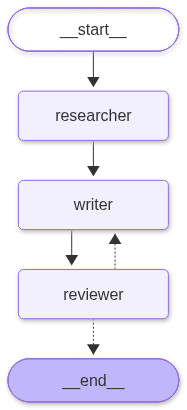

In [33]:
from IPython.display import Image, display

display(Image(release_note_team.get_graph().draw_mermaid_png()))

A compiled graph is already **one trace** in LangSmith: the graph run is the parent and every agent, model and tool call inside it is a child. No `@traceable` needed here.

In [34]:
team_result = release_note_team.invoke(
    {"topic": "What is new in LangChain 1.0 and LangGraph 1.0?", "revision_count": 0},
    config={"run_name": "Release note team"},
)

print("Drafts written:", team_result["revision_count"])
print("Approved      :", team_result["feedback"] == "")
print("\n" + team_result["draft"])

Drafts written: 1
Approved      : True

# LangChain 1.0 & LangGraph 1.0 Release Notes

## LangChain 1.0

- **Core agent loop redesign:** Build AI agents faster with the new standard `create_agent` method, replacing older APIs like `create_react_agent`.
- **Unified LLM features:** Access modern language model capabilities consistently via the new `content_blocks` property.
- **Streamlined namespace:** Focus on essential agent-building blocks; legacy functionality now in a separate `langchain-classic` package.
- **Middleware support:** Customize and extend agent behavior easily.
- **Provider-agnostic tool calling:** Standardized architecture for flexible integration of different model providers and content types.

## LangGraph 1.0

- **Stability and smooth upgrades:** Core graph APIs and execution model remain unchanged.
- **Durable execution:** Checkpointing, persistence, streaming, and human-in-the-loop features are maintained.
- **Improved ergonomics:** Better type safety and document

## 7. Subgraphs: a customer ticket router

**Use case:** a company routes every incoming ticket. A reusable **support desk** module classifies the ticket and drafts a reply. Billing tickets also go to a separate **billing team** module.

**Market need:** big systems are built from small, testable modules. In LangGraph, a compiled graph can be used **inside** another graph.

There are two ways to plug a subgraph in:

| Way | When to use | In this example |
|---|---|---|
| **A. Add the subgraph as a node** | Parent and subgraph **share** state keys | `support_desk` shares `message`, `category`, `reply` |
| **B. Call the subgraph inside a node** | Subgraph has a **different** (private) state | `billing_team` has its own `invoice_issue`, `decision` |

Docs: [Subgraphs](https://docs.langchain.com/oss/python/langgraph/use-subgraphs)

In [35]:
import csv

with open(DATA_FOLDER / "tickets.csv", newline="") as file:
    tickets = list(csv.DictReader(file))

for ticket in tickets:
    print(ticket["ticket_id"], ticket["tier"].ljust(10), ticket["message"])

T-4049 enterprise Our whole checkout API returns error 503 since 9am. We are losing sales every minute.
T-4050 free       How do I change the colour of my dashboard?
T-4051 enterprise After rotating our API keys every request fails with 401 Unauthorized.
T-4052 pro        We were charged for the Enterprise plan but we are on Pro. Please fix the invoice.
T-4053 pro        Our webhooks stopped arriving yesterday evening.


**Subgraph 1: support desk** (shares keys with the parent)

In [36]:
from typing import Literal


class SupportDeskState(TypedDict):
    message: str
    category: str
    reply: str


class TicketCategory(BaseModel):
    category: Literal["technical", "billing", "how-to"]

In [37]:
# What the subgraph state looks like (it is just a dict)
example_desk_state: SupportDeskState = {
    "message": "Our webhooks stopped arriving yesterday evening.",
    "category": "technical",
    "reply": "Please check the delivery log under Settings > Webhooks.",
}
print(example_desk_state)

# Structured output: the model must return one of the 3 allowed categories
print(TicketCategory(category="billing"))

try:
    TicketCategory(category="sales")  # not in the Literal list
except Exception as error:
    print("Rejected:", type(error).__name__)

{'message': 'Our webhooks stopped arriving yesterday evening.', 'category': 'technical', 'reply': 'Please check the delivery log under Settings > Webhooks.'}
category='billing'
Rejected: ValidationError


In [38]:

classifier_model = init_chat_model(MODEL_NAME, temperature=0).with_structured_output(TicketCategory)


def classify_ticket(state: SupportDeskState):
    result = classifier_model.invoke(f"Classify this support ticket: {state['message']}")
    return {"category": result.category}


# Try the classifier on its own with the billing ticket
classify_ticket({"message": tickets[3]["message"], "category": "", "reply": ""})

{'category': 'billing'}

In [39]:

def draft_reply(state: SupportDeskState):
    help_article = lookup_knowledge_base.invoke(state["message"])
    reply = model.invoke(
        f"Write a short, friendly reply (max 3 sentences) to this ticket.\n"
        f"Ticket: {state['message']}\nHelpful article: {help_article}"
    )
    return {"reply": reply.content}

In [40]:
# Try the reply node on its own with the first ticket
draft_reply({"message": tickets[0]["message"], "category": "technical", "reply": ""})

{'reply': 'Hi! Sorry to hear about the issue with the checkout API. Please check the worker pool on the status dashboard and restart any unhealthy workers using `nwctl workers restart --unhealthy`. If more than 30% are down, please open a P1 incident so we can assist you urgently.'}

In [41]:



desk_builder = StateGraph(SupportDeskState)
desk_builder.add_node("classify", classify_ticket)
desk_builder.add_node("draft_reply", draft_reply)
desk_builder.add_edge(START, "classify")
desk_builder.add_edge("classify", "draft_reply")
desk_builder.add_edge("draft_reply", END)

support_desk = desk_builder.compile()

**Subgraph 2: billing team** (its own private state)

In [42]:
class BillingState(TypedDict):
    invoice_issue: str
    decision: str


def decide_refund(state: BillingState):
    result = model.invoke(
        "You are a billing specialist. Policy: wrong-plan charges get a prorated refund within 5 business days. "
        f"In one sentence, state the decision for: {state['invoice_issue']}"
    )
    return {"decision": result.content}


In [43]:
# Try the billing node on its own with a sample invoice problem
decide_refund({"invoice_issue": tickets[3]["message"], "decision": ""})

{'decision': 'We will issue a prorated refund for the incorrect Enterprise plan charge within 5 business days and correct your invoice to reflect the Pro plan.'}

In [44]:


billing_builder = StateGraph(BillingState)
billing_builder.add_node("decide_refund", decide_refund)
billing_builder.add_edge(START, "decide_refund")
billing_builder.add_edge("decide_refund", END)

billing_team = billing_builder.compile()

**Parent graph: ticket router**

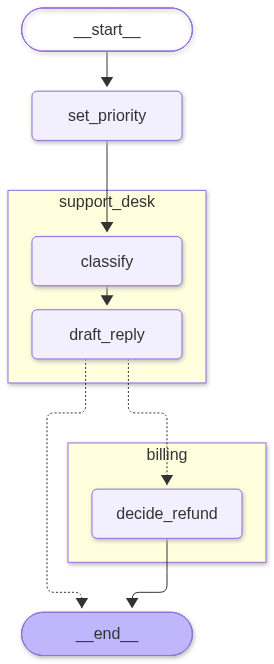

In [45]:
class TicketState(TypedDict):
    ticket_id: str
    customer: str
    tier: str
    message: str
    priority: str
    category: str
    reply: str
    billing_decision: str


def set_priority(state: TicketState):
    priority = "P1" if state["tier"] == "enterprise" else "P3"
    return {"priority": priority}


def send_to_billing(state: TicketState):
    # Way B: translate parent state -> subgraph state, call it, translate back
    billing_result = billing_team.invoke({"invoice_issue": state["message"], "decision": ""})
    return {"billing_decision": billing_result["decision"]}


def billing_or_done(state: TicketState):
    return "billing" if state["category"] == "billing" else END


router_builder = StateGraph(TicketState)
router_builder.add_node("set_priority", set_priority)
router_builder.add_node("support_desk", support_desk)  # Way A: the compiled subgraph IS the node
router_builder.add_node("billing", send_to_billing)    # Way B: a normal node that calls the subgraph

router_builder.add_edge(START, "set_priority")
router_builder.add_edge("set_priority", "support_desk")
router_builder.add_conditional_edges("support_desk", billing_or_done, ["billing", END])
router_builder.add_edge("billing", END)

ticket_router = router_builder.compile()

display(Image(ticket_router.get_graph(xray=True).draw_mermaid_png()))

**Streaming with `subgraphs=True`** shows which graph each update comes from. `()` is the parent; `('support_desk:...',)` is inside the subgraph.

In [46]:
first_ticket = tickets[0]

for namespace, update in ticket_router.stream(first_ticket, subgraphs=True, stream_mode="updates"):
    where = "parent" if namespace == () else namespace[0].split(":")[0]
    for node_name, node_output in update.items():
        print(f"[{where:12}] {node_name:14} -> {list(node_output or {})}")

[parent      ] set_priority   -> ['priority']


[support_desk] classify       -> ['category']


[support_desk] draft_reply    -> ['reply']
[parent      ] support_desk   -> ['message', 'category', 'reply']


Now process **all** tickets in parallel with `.batch()`, wrapped in `@traceable` so the whole run is one trace.

In [47]:
@traceable(name="Route all tickets")
def route_all_tickets(ticket_list):
    return ticket_router.batch(ticket_list)


routed_tickets = route_all_tickets(tickets)

for ticket in routed_tickets:
    print(f"{ticket['ticket_id']} | {ticket['priority']} | {ticket['category']:9} | {ticket['customer']}")
    print("   reply  :", ticket["reply"])
    if ticket.get("billing_decision"):
        print("   billing:", ticket["billing_decision"])
    print()

T-4049 | P1 | technical | Alice Corp
   reply  : Hi! Sorry to hear about the issue with the checkout API. Please check the worker pool on the status dashboard and restart any unhealthy workers using `nwctl workers restart --unhealthy`. If more than 30% are down, please open a P1 incident so we can assist you urgently.

T-4050 | P3 | how-to    | Bob's Bakery
   reply  : Hi! To change the color of your dashboard, please check your dashboard settings or customization options within the app. If you need more detailed steps, feel free to let me know!

T-4051 | P1 | technical | Cygnus Health
   reply  : Thanks for reaching out! After rotating your API keys, please make sure to update the new key in every service’s secret store and redeploy them. Also, double-check that the client machine’s clock is accurate, as a time difference over 5 minutes can cause 401 errors.

T-4052 | P3 | billing   | Delta Tutors
   reply  : Thanks for reaching out! Since plan changes take effect at the next billing 

## 8. LangSmith evaluation: is our summarizer good enough?

**Use case:** before changing the prompt or the model, the analyst team wants proof that summaries stay correct.

**Market need:** test LLM apps like normal software. LangSmith runs your app on a **dataset** of examples and scores each answer with **evaluators**. Every run is saved as an **experiment** you can compare later.

```
dataset (inputs + expected outputs) -> your app -> evaluators -> scores in LangSmith
```

Docs: [Evaluation quickstart](https://docs.langchain.com/langsmith/evaluation-quickstart)

In [48]:
from langsmith import Client

langsmith_client = Client()
DATASET_NAME = "earnings-summaries-demo"

if not langsmith_client.has_dataset(dataset_name=DATASET_NAME):
    dataset = langsmith_client.create_dataset(dataset_name=DATASET_NAME, description="Made-up earnings reports")
    langsmith_client.create_examples(
        dataset_id=dataset.id,
        examples=[
            {"inputs": {"earnings_text": report["text"]}, "outputs": {"revenue": report["revenue"]}}
            for report in earnings_reports
        ],
    )

print("Dataset ready:", DATASET_NAME)

Dataset ready: earnings-summaries-demo


In [49]:
def summarize_for_eval(inputs: dict) -> dict:
    """The app we are testing: our LCEL chain from section 2."""
    return {"summary": summary_chain.invoke(inputs)}


def mentions_revenue(outputs: dict, reference_outputs: dict) -> bool:
    """Does the summary include the correct revenue figure?"""
    return reference_outputs["revenue"] in outputs["summary"]


def has_two_bullets(outputs: dict) -> bool:
    """Does the summary have exactly 2 bullet points?"""
    bullet_lines = [line for line in outputs["summary"].splitlines() if line.strip().startswith(("-", "*", "•"))]
    return len(bullet_lines) == 2


eval_results = langsmith_client.evaluate(
    summarize_for_eval,
    data=DATASET_NAME,
    evaluators=[mentions_revenue, has_two_bullets],
    experiment_prefix="earnings-summary-gpt-4.1-mini",
)

View the evaluation results for experiment: 'earnings-summary-gpt-4.1-mini-25f2f3af' at:
https://aws.smith.langchain.com/o/c6f8a9e8-f049-4a50-934c-a7ce8381eeb3/datasets/6ab1e1d2-c70d-4383-94e2-66a9f5749c09/compare?selectedSessions=755e053e-e768-4bdd-a430-877cd5b5be99




In [50]:
def print_scores(experiment_results):
    for row in experiment_results:
        scores = {result.key: result.score for result in row["evaluation_results"]["results"]}
        print(row["example"].outputs["revenue"].ljust(6), scores)


print_scores(eval_results)

$1.1B  {'mentions_revenue': False, 'has_two_bullets': True}
$2.4B  {'mentions_revenue': False, 'has_two_bullets': True}
$5.8B  {'mentions_revenue': False, 'has_two_bullets': True}
$640M  {'mentions_revenue': False, 'has_two_bullets': True}


**Did `mentions_revenue` fail?** Models like to rewrite `$2.4B` as `$2.4 billion`. A person reads both the same, but our strict check does not, and a downstream system parsing the summary might not either.

This is exactly why we evaluate: we found a problem **before** users did. Let's fix the prompt and run a second experiment on the same dataset.

In [51]:
summary_prompt_v2 = ChatPromptTemplate.from_messages([
    ("system", "You are an expert financial analyst. Summarize the earnings report in exactly 2 bullet points. "
               "Always mention the revenue figure, copied exactly as written in the report (for example $2.4B)."),
    ("user", "{earnings_text}"),
])

summary_chain_v2 = summary_prompt_v2 | model | StrOutputParser()


def summarize_for_eval_v2(inputs: dict) -> dict:
    return {"summary": summary_chain_v2.invoke(inputs)}


eval_results_v2 = langsmith_client.evaluate(
    summarize_for_eval_v2,
    data=DATASET_NAME,
    evaluators=[mentions_revenue, has_two_bullets],
    experiment_prefix="earnings-summary-gpt-4.1-mini-v2-prompt",
)

print_scores(eval_results_v2)

View the evaluation results for experiment: 'earnings-summary-gpt-4.1-mini-v2-prompt-64f3657b' at:
https://aws.smith.langchain.com/o/c6f8a9e8-f049-4a50-934c-a7ce8381eeb3/datasets/6ab1e1d2-c70d-4383-94e2-66a9f5749c09/compare?selectedSessions=2442503c-c44f-4dc3-a3a8-42f7f898dbbb




$1.1B  {'mentions_revenue': True, 'has_two_bullets': True}
$2.4B  {'mentions_revenue': True, 'has_two_bullets': True}
$5.8B  {'mentions_revenue': True, 'has_two_bullets': True}
$640M  {'mentions_revenue': True, 'has_two_bullets': True}


In LangSmith, open the dataset, tick both experiments and click **Compare** to see the scores side by side.

## What to look at in LangSmith

Open [smith.langchain.com](https://smith.langchain.com). You should see **one trace per example**:

| Trace | What is inside |
|---|---|
| Earnings summaries (batch) | 4 parallel chain runs |
| Expense compliance checks | 4 agent runs |
| Support conversation | 3 turns, with knowledge-base and Exa tool calls |
| Long chat with summarization | the summarization call, then the answer |
| Release note team | researcher, writer and reviewer (and any revisions) |
| Route all tickets | 5 ticket runs, each with its subgraph steps |

Click any trace to see the inputs, outputs, tokens, cost and latency of every step. The evaluation results are under **Datasets & Experiments → earnings-summaries-demo**.

**Try it yourself**
1. Change `MODEL_NAME` and rerun section 8. Compare the two experiments in LangSmith.
2. Add a new article to `data/knowledge_base.json` and ask the support agent about it.
3. Lower the summarization `trigger` to `("tokens", 500)` and see what changes.